# 02 · Songs

Questions about the songs The Current has played since Dec. 22, 2005.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from plays import load_plays, display_names, fmt_duration

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE = "#2a78d6"

plays = load_plays()           # every logged entry
music = plays[plays.is_music]  # just the songs (see 01_scrape.ipynb → "What isn't a song?")

## How many songs have been played?

In [2]:
print(f"{len(plays):,} entries in the playlist log")
print(f"{len(music):,} of them are songs; the other {len(plays) - len(music):,} are shows, segments, interviews and clips")

2,477,899 entries in the playlist log
2,472,327 of them are songs; the other 5,572 are shows, segments, interviews and clips


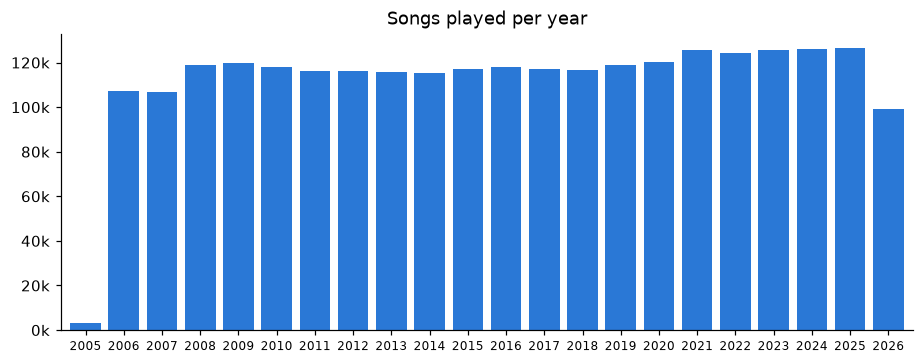

2005 is only 10 days and the current year is partial.


In [3]:
per_year = music.groupby(music.played_at.dt.year).size()

ax = per_year.plot.bar(color=BLUE, width=0.8, figsize=(10, 3.5))
ax.set(title="Songs played per year", xlabel="", ylabel="")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.tick_params(axis="x", rotation=0, labelsize=8)
plt.show()
print("2005 is only 10 days and the current year is partial.")

## How many unique songs?

We count a song as a unique **title + artist** (`song_key`), so the same song on an album, a single and a
"Live Current" compilation counts once. The station's own `song_id` splits those versions apart, so it gives a higher number.

In [4]:
n_songs = music.song_key.nunique()
plays_per_song = music.song_key.value_counts()

print(f"{n_songs:,} unique songs (title + artist)")
print(f"{music.song_id.nunique():,} unique song_ids (counts each album/version separately)")
print(f"{(plays_per_song == 1).sum():,} songs ({(plays_per_song == 1).mean():.0%}) were played exactly once")
print(f"Half of all plays went to the top {(plays_per_song.cumsum() < len(music) / 2).sum() + 1:,} songs "
      f"({((plays_per_song.cumsum() < len(music) / 2).sum() + 1) / n_songs:.1%} of songs)")

93,691 unique songs (title + artist)
123,248 unique song_ids (counts each album/version separately)
37,533 songs (40%) were played exactly once
Half of all plays went to the top 4,114 songs (4.4% of songs)


## What's the longest song The Current has played?

The longest *entries* in the log are shows and full concerts (60–90 minutes), and even after filtering, some one-off
entries have typo'd durations. So we look at songs **in rotation**, meaning played at least 5 times, and use each song's
typical (median) logged length.

In [5]:
MIN_PLAYS = 5

songs = (
    music.dropna(subset=["seconds"])
    .groupby("song_key")
    .agg(plays=("play_id", "size"), seconds=("seconds", "median"))
    .join(display_names(music, "song_key", ["title", "artist", "album"]))
)
in_rotation = songs[songs.plays >= MIN_PLAYS]


def show(df):
    return df.assign(length=df.seconds.map(fmt_duration))[["title", "artist", "album", "length", "plays"]]


show(in_rotation.nlargest(15, "seconds"))

,title,artist,album,length,plays
song_key,,,,,
slide show|travis,Slide Show,Travis,The Man Who,18:31,13
spanish key|miles davis,Spanish Key,Miles Davis,Bitches Brew,17:35,43
murder most foul|bob dylan,Murder Most Foul,Bob Dylan,Rough and Rowdy Ways,16:55,15
blue monk|thelonious monk quartet and john coltrane,Blue Monk,Thelonious Monk Quartet and John Coltrane,At Carnegie Hall,16:29,6
the prayer|the world experience orchestra,The Prayer,The World Experience Orchestra,Gilles Peterson Digs America: Brownswood USA,14:41,5
duk koo kim|sun kil moon,Duk Koo Kim,Sun Kil Moon,Ghosts of the Great Highway,14:33,5
miles runs the voodoo down|miles davis,Miles Runs the Voodoo Down,Miles Davis,Bitches Brew,14:04,48
moonlight|mono,Moonlight,Mono,You Are There,12:57,7
zombie|fela kuti,Zombie,Fela Kuti,Zombie,12:26,50


In [6]:
# For comparison: the longest single entries in the raw log, before any filtering
raw = plays.nlargest(10, "seconds")[["played_at", "title", "artist", "duration"]]
raw

,played_at,title,artist,duration
1781616,2021-04-01 20:07:34-05:00,Virtual Session,tUnE-yArDs,1414:30
2005803,2023-01-16 09:00:00-06:00,MLK Remembered,NaN,240:00
650487,2011-08-17 21:56:51-05:00,Passport Approved,Sat Bisla,120:00
652758,2011-08-24 21:59:27-05:00,Passport Approved,Hosted by Sat Bisla,120:00
657226,2011-09-07 21:53:03-05:00,Passport Approved,Hosted by Sat Bisla,120:00
661631,2011-09-21 22:00:09-05:00,Passport Approved,Hosted by Sat Bisla,120:00
663858,2011-09-28 21:58:34-05:00,Passport Approved,Hosted by Sat Bisla,120:00
670129,2011-10-19 21:57:41-05:00,Passport Approved,Hosted by Sat Bisla,120:00
672226,2011-10-26 21:57:21-05:00,Passport Approved,Hosted by Sat Bisla,120:00
674426,2011-11-02 21:59:47-05:00,Passport Approved,Hosted by Sat Bisla,120:00


## What's the shortest?

In [7]:
show(in_rotation.nsmallest(15, "seconds"))

,title,artist,album,length,plays
song_key,,,,,
the local show legacy uw|derrick stevens,The Local Show Legacy UW,Derrick Stevens,The Local Show,0:05,7
billy bragg talks to himself|billy bragg,Billy Bragg Talks To Himself,Billy Bragg,Still Looking For A New England 1 of 2,0:15,12
i like food|descendents,I Like Food,Descendents,FAT,0:15,8
her majesty|the beatles,Her Majesty,The Beatles,Abbey Road (2009 Remaster),0:26,24
stop the dams|gorillaz,Stop The Dams,Gorillaz,D-Sides,0:27,9
"youth brigade , i object|twenty years of dischord","Youth Brigade , I Object",Twenty Years of Dischord,Rare and Unreleased,0:29,7
happy birthday|lizzo,Happy Birthday,Lizzo,Recorded Live at The Current's 9th Birthday Party,0:36,6
"state of alert , draw blank|twenty years of dischord","State of Alert , Draw Blank",Twenty Years of Dischord,Rare and Unreleased,0:39,6
the humours of whiskey (traditional)|hozier,The Humours of Whiskey (Traditional),Hozier,89.3 In-Studio Performance,0:45,10


In [8]:
# Without the 5-play rule, the shortest "songs" are mostly sound clips and logging errors:
show(songs.nsmallest(10, "seconds"))

,title,artist,album,length,plays
song_key,,,,,
i remember romance|flamin oh's,I Remember Romance,Flamin Oh's,NaN,0:01,1
there's a snake in my boot|toy story,There's a snake in my boot,Toy Story,Clips,0:03,1
a festivus for the rest of us|seinfeld,A Festivus for the rest of us,Seinfeld,Clips,0:04,1
happy little cloud|bob ross,Happy Little Cloud,Bob Ross,NaN,0:04,1
hey all you cool cats and kittens!|carole baskins,Hey all you cool cats and kittens!,Carole Baskins,Tiger King,0:04,1
you won't believe what this snake is doing|harry potter and the sorcerer's stone,You won't believe what this snake is doing,Harry Potter and the Sorcerer's Stone,Clips,0:04,1
"""i believe i ordered the large cappuccino""|so i married an axe murderer","""I believe I ordered the large cappuccino""",So I Married an Axe Murderer,Clips,0:05,1
"""i'm the king of the world""|leonardo dicaprio","""I'm the King of the World""",Leonardo Dicaprio,Titanic,0:05,1
fiona instagram|fiona apple,Fiona instagram,Fiona Apple,Clips,0:05,1


## What's the most played song?

In [9]:
top_songs = (
    plays_per_song.rename("plays").to_frame()
    .join(display_names(music, "song_key", ["title", "artist"]))
    .join(music.groupby("song_key").played_at.agg(first_played="min", last_played="max"))
)
top_songs["first_played"] = top_songs.first_played.dt.strftime("%Y-%m-%d")
top_songs["last_played"] = top_songs.last_played.dt.strftime("%Y-%m-%d")
top_songs = top_songs[["title", "artist", "plays", "first_played", "last_played"]]
top_songs.head(25)

,title,artist,plays,first_played,last_played
song_key,,,,,
home|edward sharpe and the magnetic zeros,Home,Edward Sharpe and The Magnetic Zeros,661,2009-09-21,2026-09-08
transmission|joy division,Transmission,Joy Division,656,2006-01-03,2026-10-03
bloodbuzz ohio|the national,Bloodbuzz Ohio,The National,649,2010-03-24,2026-09-21
not the kid|communist daughter,Not the Kid,Communist Daughter,646,2009-09-20,2026-10-10
wandering star|polica,Wandering Star,Polica,635,2011-09-09,2026-10-05
hollywood forever cemetery sings|father john misty,Hollywood Forever Cemetery Sings,Father John Misty,628,2012-02-06,2026-09-22
ho hey|the lumineers,Ho Hey,The Lumineers,627,2012-02-20,2026-10-08
my girls|animal collective,My Girls,Animal Collective,621,2009-01-10,2026-10-03
dance yrself clean|lcd soundsystem,Dance Yrself Clean,LCD Soundsystem,621,2010-05-24,2026-09-16


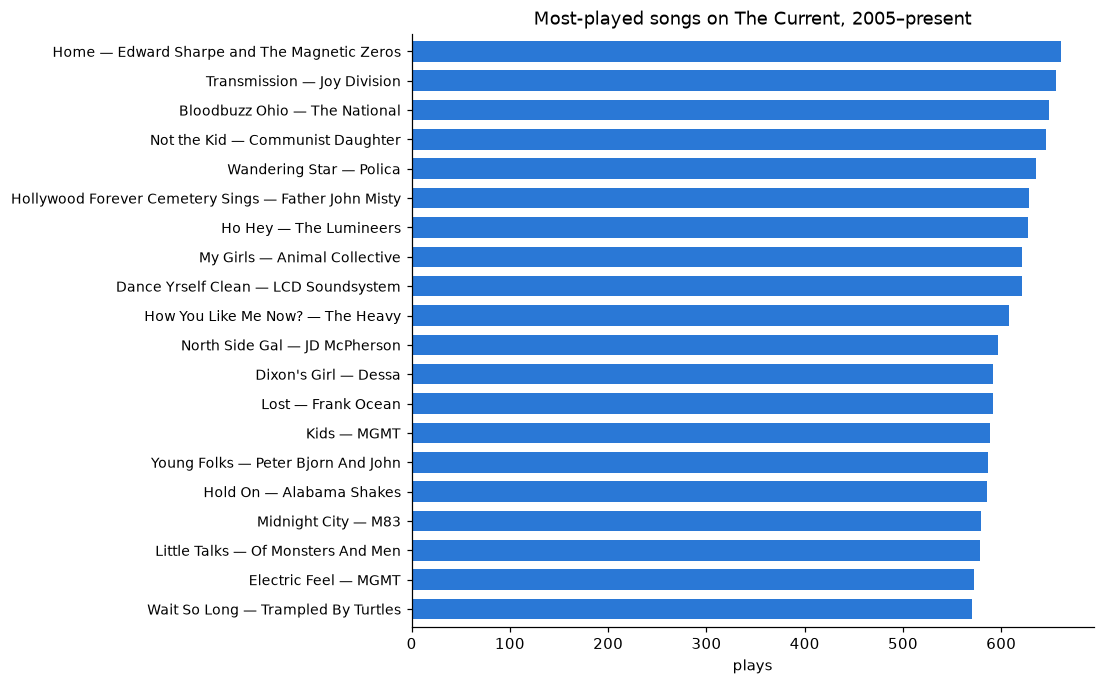

In [10]:
top20 = top_songs.head(20).iloc[::-1]
ax = top20.plays.plot.barh(color=BLUE, figsize=(8, 7), width=0.7)
ax.set_yticklabels([f"{t} — {a}" for t, a in zip(top20.title, top20.artist)], fontsize=9)
ax.set(title="Most-played songs on The Current, 2005–present", xlabel="plays", ylabel="")
plt.show()

In [11]:
# Most-played song of each year
year = music.played_at.dt.year.rename("year")
by_year = music.groupby([year, "song_key"]).size().rename("plays").reset_index()
top_each_year = (
    by_year.sort_values(["year", "plays"], ascending=[True, False])
    .drop_duplicates("year")
    .join(display_names(music, "song_key", ["title", "artist"]), on="song_key")
    .set_index("year")[["title", "artist", "plays"]]
)
top_each_year

,title,artist,plays
year,,,
2005,Better Version of Me,Fiona Apple,4
2006,Destroy Everything You Touch,Ladytron,67
2007,Young Folks,Peter Bjorn And John,105
2008,2080,Yeasayer,234
2009,People Got A Lotta Nerve,Neko Case,244
2010,O.N.E.,Yeasayer,285
2011,Pumped Up Kicks,Foster the People,341
2012,Ho Hey,The Lumineers,351
2013,Feels Like We Only Go Backwards,Tame Impala,255


## Is there a running popularity chart? Which song was #1, and what replaced it?

A Billboard-style chart. Every week (Monday–Sunday), songs are ranked by how many times they were played over the
last `WINDOW_WEEKS` weeks. A 4-week window smooths out week-to-week noise. Set it to 1 for a strict weekly chart.
Ties go to the song with more total plays to date. Partial weeks at the start and end of the data are dropped.

To keep the math fast, only songs that ever ranked in some single week's top 40 are charted. Any song that could
reach the top of a 4-week chart is in that group.

In [12]:
WINDOW_WEEKS = 4

week = music.played_at.dt.tz_localize(None).dt.to_period("W-SUN").dt.start_time.rename("week")
days_in_week = music.groupby(week).played_at.apply(lambda s: s.dt.date.nunique())
full_weeks = days_in_week[days_in_week == 7].index

weekly = music.groupby([week, "song_key"]).size().rename("plays").reset_index()
weekly = weekly[weekly.week.isin(full_weeks)]
contenders = weekly[weekly.groupby("week").plays.rank(ascending=False, method="min") <= 40].song_key.unique()

by_week = weekly[weekly.song_key.isin(contenders)].pivot(index="week", columns="song_key", values="plays").fillna(0)
chart_plays = by_week.rolling(WINDOW_WEEKS).sum().iloc[WINDOW_WEEKS - 1:]
plays_to_date = by_week.cumsum().loc[chart_plays.index]

chart = (
    pd.concat({"plays": chart_plays.stack(), "plays_to_date": plays_to_date.stack()}, axis=1)
    .query("plays > 0")
    .astype({"plays": int, "plays_to_date": int})
    .reset_index()
    .sort_values(["week", "plays", "plays_to_date"], ascending=[True, False, False])
)
chart["rank"] = chart.groupby("week").cumcount() + 1
chart = chart[chart["rank"] <= 100]  # a "Hot 100"

names = display_names(music, "song_key", ["title", "artist"])
chart = chart.join(names, on="song_key")


def hot10(week_of):
    """The top 10 for the week containing `week_of` (any date string)."""
    start = pd.Timestamp(week_of).to_period("W-SUN").start_time
    return chart[(chart.week == start) & (chart["rank"] <= 10)].set_index("rank")[["title", "artist", "plays"]]


hot10("2012-06-15")

,title,artist,plays
rank,,,
1,Are You Gonna Waste My Time?,Zeus,52
2,Strange Attractor,Animal Kingdom,51
3,This Head I Hold,Electric Guest,49
4,The Only Place,Best Coast,49
5,Say Goodbye,Norah Jones,49
6,Lonesome,Dr. Dog,48
7,The Look,Metronomy,47
8,Bloody Mary (Nerve Endings),Silversun Pickups,47
9,Myth,Beach House,47


In [13]:
# Every run at #1, in order, with the song that replaced it
no1 = chart[chart["rank"] == 1].reset_index(drop=True)
no1["run"] = (no1.song_key != no1.song_key.shift()).cumsum()

runs = no1.groupby("run").agg(
    title=("title", "first"), artist=("artist", "first"), song_key=("song_key", "first"),
    first_week=("week", "min"), weeks_at_1=("week", "size"),
)
runs["succeeded_by"] = (runs.title.shift(-1) + " — " + runs.artist.shift(-1)).fillna("(current #1)")
runs["first_week"] = runs.first_week.dt.strftime("%Y-%m-%d")

print(f"{len(runs):,} runs at #1 by {runs.song_key.nunique():,} different songs over {len(no1):,} weeks; "
      f"the typical run lasts {runs.weeks_at_1.median():.0f} week(s), the longest {runs.weeks_at_1.max()}.")
runs.drop(columns="song_key").tail(20)

685 runs at #1 by 623 different songs over 1,080 weeks; the typical run lasts 1 week(s), the longest 6.


,title,artist,first_week,weeks_at_1,succeeded_by
run,,,,,
666,Where's My Phone,Mitski,2026-03-30,1,Prize Fighter — Jean Dawson
667,Prize Fighter,Jean Dawson,2026-04-06,1,Heavy Foot — Mon Rovia
668,Heavy Foot,Mon Rovia,2026-04-13,1,Victim Of Luck — Metric
669,Victim Of Luck,Metric,2026-04-20,1,Riptides — Death Cab for Cutie
670,Riptides,Death Cab for Cutie,2026-04-27,1,Kill Me — Hayley Williams
671,Kill Me,Hayley Williams,2026-05-04,1,War is a God — Jesse Welles
672,War is a God,Jesse Welles,2026-05-11,1,Rein Me In feat. Olivia Dean — Sam Fender
673,Rein Me In feat. Olivia Dean,Sam Fender,2026-05-18,1,House of I — The Afghan Whigs
674,House of I,The Afghan Whigs,2026-05-25,1,Fade Into You — Gregory Alan Isakov and Sylvan Esso


Unlike a pop chart, the #1 spot on The Current rarely lasts more than a few weeks. The top songs each get roughly
15 plays a week, and several others are right behind them. So **weeks in the top 10** is a better measure of a song's
staying power than weeks at #1.

In [14]:
# Biggest chart runs of all time
staying_power = (
    chart.groupby("song_key")
    .agg(weeks_in_top_10=("rank", lambda r: (r <= 10).sum()), weeks_at_1=("rank", lambda r: (r == 1).sum()),
         peak=("rank", "min"), first_charted=("week", "min"))
    .join(names)
    .sort_values(["weeks_in_top_10", "weeks_at_1"], ascending=False)
    .reset_index(drop=True)
)
staying_power["first_charted"] = staying_power.first_charted.dt.strftime("%Y-%m-%d")
staying_power[["title", "artist", "weeks_in_top_10", "weeks_at_1", "peak", "first_charted"]].head(20)

,title,artist,weeks_in_top_10,weeks_at_1,peak,first_charted
0,Dancing Girls And Dancing Men,Robert Pollard,16,1,1,2006-01-30
1,Lottery,Jade Bird,15,3,1,2018-01-22
2,Truth Is,Brother Ali,14,3,1,2007-01-22
3,Destroy Everything You Touch,Ladytron,14,2,1,2006-01-16
4,Silver Lining,Rilo Kiley,14,0,4,2007-08-06
5,Honey,Samia,13,3,1,2023-02-06
6,Someday Baby,Bob Dylan,13,2,1,2006-09-25
7,Vertigo,Alice Merton,13,2,1,2021-04-12
8,Live With Me,Massive Attack,12,7,1,2006-04-17
9,Le Territoire,Brazilian Girls,12,3,1,2006-10-02


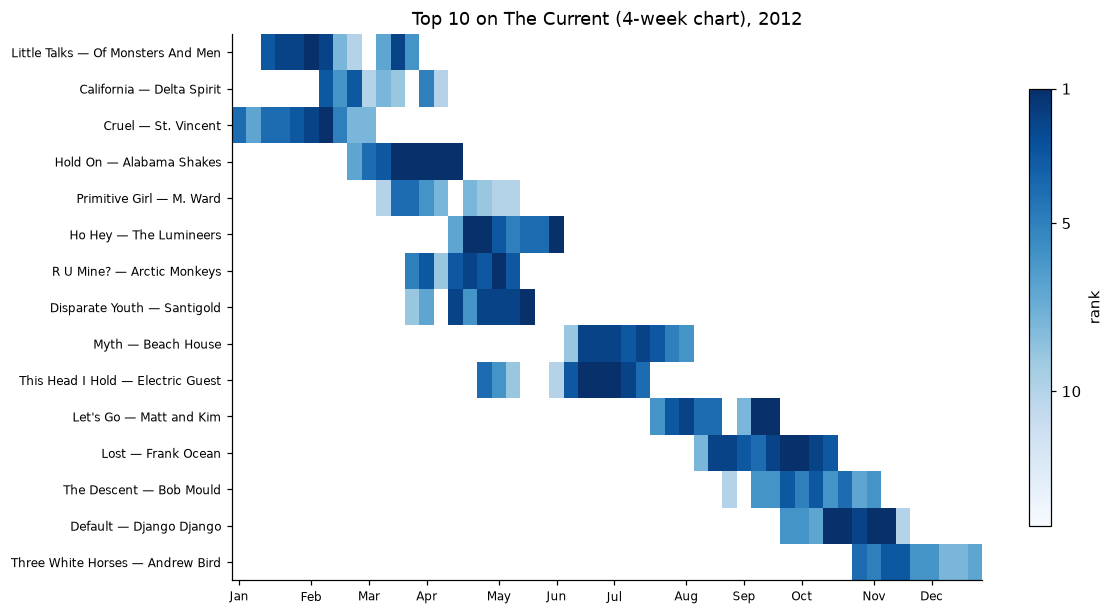

In [15]:
# One year on the chart: the 15 songs with the most weeks in the top 10 that year.
# Darker = higher rank; blank = outside the top 10. Read it left to right to see songs rise, peak and get replaced.
YEAR = 2012  # change me

yr = chart[(chart.week.dt.year == YEAR) & (chart["rank"] <= 10)]
top_songs_yr = yr.song_key.value_counts().head(15).index
grid = yr[yr.song_key.isin(top_songs_yr)].pivot(index="song_key", columns="week", values="rank")
grid = grid.loc[grid.idxmin(axis=1).sort_values().index]  # order songs by when they peaked

fig, ax = plt.subplots(figsize=(11, 0.35 * len(grid) + 1.2))
im = ax.imshow(grid, aspect="auto", cmap="Blues_r", vmin=1, vmax=14, interpolation="nearest")
ax.set_yticks(range(len(grid)))
ax.set_yticklabels([f"{names.loc[k, 'title']} — {names.loc[k, 'artist']}" for k in grid.index], fontsize=8)
months = [i for i, w in enumerate(grid.columns) if w.day <= 7]
ax.set_xticks(months)
ax.set_xticklabels([grid.columns[i].strftime("%b") for i in months], fontsize=8)
ax.set_title(f"Top 10 on The Current ({WINDOW_WEEKS}-week chart), {YEAR}")
fig.colorbar(im, ax=ax, ticks=[1, 5, 10], label="rank", shrink=0.8).ax.invert_yaxis()
plt.show()